# DataTrust — Resumen del proyecto

**No es un entregable oficial** — es una herramienta de trabajo para explicar el
proyecto de forma guiada, con el codigo real que produce cada numero, no solo
texto. Sigue la misma logica que `check_impacto_negocio_profesional.py` y los
notebooks 01-06, pero todo junto y en orden narrativo.

**Pregunta central**: ¿Como afectan los problemas de calidad de datos a las
conclusiones de negocio y al rendimiento de un modelo predictivo, en un caso
real de alquiler turistico en Barcelona?


In [1]:
import pandas as pd

pd.set_option("display.max_columns", None)
listings = pd.read_csv("data/airbnb_bcn/listings.csv", low_memory=False)
print(f"Alojamientos: {len(listings):,}".replace(",", "."))


Alojamientos: 15.293


## 1. El hallazgo de apertura

Mas de la mitad del inventario tiene al menos un problema de calidad
(licencia no verificable, precio ausente, datos estructurales incompletos, o
sin ninguna valoracion).


In [2]:
sin_licencia_ok = listings["license"].isna() | ~listings["license"].astype(str).str.contains(
    "HUTB|National registration|Exempt", case=False, na=False, regex=True
)
sin_precio = listings["price"].isna()
sin_estructura = listings[["bedrooms", "bathrooms", "beds"]].isna().any(axis=1)
sin_valoracion = listings["number_of_reviews"] == 0

al_menos_un_problema = sin_licencia_ok | sin_precio | sin_estructura | sin_valoracion
pct = al_menos_un_problema.mean() * 100
print(f"Alojamientos con al menos una incidencia de calidad: {pct:.1f}%")


Alojamientos con al menos una incidencia de calidad: 51.4%


## 2. El hallazgo central: por que un piso ocupado puede mostrar 0 € de ingreso

`estimated_revenue_l365d` (el ingreso estimado) se calcula como **ocupacion
estimada × precio**. La ocupacion sale de las resenas del ultimo año,
asumiendo que el 50% de los huespedes resena (suposicion de Inside Airbnb,
rango admitido 30,5%-72%, fuente: insideairbnb.com/data-assumptions).

Un huesped con estancia de 28+ noches deja como mucho 1 resena al año → el
sistema puede registrar 0 resenas recientes → ocupacion estimada 0 → ingreso
0, aunque el piso este ocupado y generando dinero real.


In [3]:
listings["profesional"] = listings["calculated_host_listings_count"] > 50
tiene_revenue = listings["estimated_revenue_l365d"].notna()
es_cero = listings["estimated_revenue_l365d"] == 0

zero_pro = listings[tiene_revenue & es_cero & listings["profesional"]]
activo_pro = listings[tiene_revenue & ~es_cero & listings["profesional"]]

pct_zero = es_cero[tiene_revenue & listings["profesional"]].mean() * 100
pct_sin_resenas = (zero_pro["number_of_reviews_ltm"] == 0).mean() * 100
pct_estancia_larga_zero = (zero_pro["minimum_nights"] >= 28).mean() * 100
pct_estancia_larga_activo = (activo_pro["minimum_nights"] >= 28).mean() * 100

print(f"Profesionales con ingreso 0 EUR:            {pct_zero:.1f}%")
print(f"  de ellos, sin resenas en el ultimo año:    {pct_sin_resenas:.1f}%")
print(f"  de ellos, con estancia >= 28 noches:        {pct_estancia_larga_zero:.1f}%")
print(f"  (vs. en profesionales activos):             {pct_estancia_larga_activo:.1f}%")


Profesionales con ingreso 0 EUR:            54.2%
  de ellos, sin resenas en el ultimo año:    100.0%
  de ellos, con estancia >= 28 noches:        62.2%
  (vs. en profesionales activos):             26.1%


**La decision de gobernanza**: no se borra, no se inventa un ingreso. Se marca
`revenue_no_estimable` solo con doble evidencia (0 resenas en el ultimo año
**y** estancia minima >= 28 noches) — para no sobrecorregir excluyendo
anuncios que de verdad rinden mal.


In [4]:
no_estimable = (
    tiene_revenue & es_cero
    & (listings["number_of_reviews_ltm"] == 0)
    & (listings["minimum_nights"] >= 28)
)
listings["revenue_no_estimable"] = no_estimable
pct_marcados = no_estimable.sum() / tiene_revenue.sum() * 100
print(f"Anuncios marcados como revenue_no_estimable: {no_estimable.sum():,} "
      f"({pct_marcados:.1f}% de los que tienen dato)".replace(",", "."))


Anuncios marcados como revenue_no_estimable: 2.686 (20.1% de los que tienen dato)


## 3. La prueba: el gap profesional vs. particular, antes y despues de auditar

Comparando dos grupos que **ya existen hoy** (anfitriones con mas de 50
anuncios en Barcelona vs. particulares) — no una decision individual de
escalar un negocio.


Gap con datos crudos:    9.660 EUR/anio/anuncio (39.7%)
Gap con datos auditados: 6.661 EUR/anio/anuncio (23.1%)


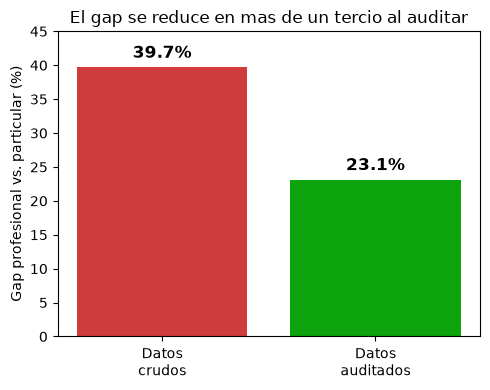

In [5]:
import matplotlib.pyplot as plt

media_naive = listings[tiene_revenue].groupby("profesional")["estimated_revenue_l365d"].mean()
media_corr = listings[tiene_revenue & ~no_estimable].groupby("profesional")["estimated_revenue_l365d"].mean()

gap_naive = media_naive[False] - media_naive[True]
gap_corr = media_corr[False] - media_corr[True]
pct_naive = gap_naive / media_naive[False] * 100
pct_corr = gap_corr / media_corr[False] * 100

print(f"Gap con datos crudos:    {gap_naive:,.0f} EUR/anio/anuncio ({pct_naive:.1f}%)".replace(",", "."))
print(f"Gap con datos auditados: {gap_corr:,.0f} EUR/anio/anuncio ({pct_corr:.1f}%)".replace(",", "."))

fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(["Datos\ncrudos", "Datos\nauditados"], [pct_naive, pct_corr],
                 color=["#d03b3b", "#0ca30c"])
ax.bar_label(barras, fmt="%.1f%%", padding=4, fontsize=12, fontweight="bold")
ax.set_ylabel("Gap profesional vs. particular (%)")
ax.set_title("El gap se reduce en mas de un tercio al auditar")
ax.set_ylim(0, 45)
plt.tight_layout()
plt.show()


## 4. La traduccion a dinero

Escalado solo como ayuda de intuicion a un grupo ilustrativo de 50 anuncios
(no una decision real de nadie — son dos poblaciones de anfitriones que ya
existen, no una persona decidiendo escalar su negocio):


In [6]:
n_grupo = 50
total_naive = gap_naive * n_grupo
total_corr = gap_corr * n_grupo
print(f"Con datos crudos:    {total_naive:,.0f} EUR/anio".replace(",", "."))
print(f"Con datos auditados: {total_corr:,.0f} EUR/anio".replace(",", "."))
print(f"Diferencia:          {total_naive - total_corr:,.0f} EUR/anio".replace(",", "."))


Con datos crudos:    483.000 EUR/anio
Con datos auditados: 333.042 EUR/anio
Diferencia:          149.958 EUR/anio


**149.958 €/año no es dinero que alguien gane o pierda** — es el tamaño del
error que tendria quien tome una decision de negocio con el dato sin auditar
en vez del auditado.


## 5. Una segunda prueba: el modelo predictivo

Resultados ya verificados y ejecutados en `notebooks/06_modelo_ml.ipynb`
(no se reentrena aqui, serian varios minutos; se muestran los resultados
finales):

| Version | n | MAE | RMSE | R² |
|---|---|---|---|---|
| Datos crudos | 13.355 | 13.310 € | 20.909 € | **0,470** |
| Curado A (capacidad) | 10.669 | 15.216 € | 23.057 € | **0,439** |
| Curado B (barrio) | 10.669 | 15.205 € | 23.037 € | **0,440** |

R² **peor** con datos tratados — no por mal tratamiento, sino porque se
excluyen los 2.686 ceros artificiales que inflaban la precision aparente del
modelo crudo. Diferencia entre criterios A y B: menor al 0,1% — la
conclusion no depende de una eleccion arbitraria de imputacion.


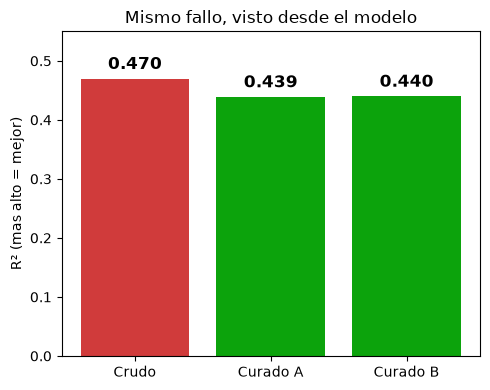

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
versiones = ["Crudo", "Curado A", "Curado B"]
r2 = [0.470, 0.439, 0.440]
colores = ["#d03b3b", "#0ca30c", "#0ca30c"]
barras = ax.bar(versiones, r2, color=colores)
ax.bar_label(barras, fmt="%.3f", padding=4, fontsize=12, fontweight="bold")
ax.set_ylabel("R² (mas alto = mejor)")
ax.set_title("Mismo fallo, visto desde el modelo")
ax.set_ylim(0, 0.55)
plt.tight_layout()
plt.show()


## 6. Limitaciones (declaradas, no escondidas)

- La curacion esta justificada y verificada mecanicamente (SQL antes/despues),
  pero no comparada contra un valor real conocido — inherente a cualquier
  imputacion.
- El target depende de una suposicion de la fuente (tasa de resenas 50%,
  rango admitido 30,5%-72%), no un dato medido.
- El 23,1% de gap que queda no esta explicado del todo: no es por tipo de
  piso (los profesionales alquilan unidades mas caras y grandes), es por
  menor actividad medida — no confirmado si es sesgo de medicion o
  diferencia real.

## 7. Conclusion

La calidad de los datos no es un detalle tecnico: cambia una conclusion de
negocio en mas de un tercio, y cambia como se evalua un modelo predictivo.
Las dos pruebas vienen de la misma correccion sobre el mismo dato
(`revenue_no_estimable`), no son dos hallazgos sueltos.
